In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nDataset information:")
df.info()

Dataset shape: (244, 7)

Columns: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicated rows
print("\nDuplicated rows:", df.duplicated().sum())

# Statistical summary
print("\nStatistical summary:")
df.describe()

Missing values:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Duplicated rows: 1

Statistical summary:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [5]:
# Remove duplicated rows
df = df.drop_duplicates()

# Verify the cleaning
print("Dataset shape after cleaning:", df.shape)
print("Duplicated rows:", df.duplicated().sum())

Dataset shape after cleaning: (243, 7)
Duplicated rows: 0


In [6]:
sales_by_day = df.groupby('day')['total_bill'].sum()

print(sales_by_day)

day
Fri      325.88
Sat     1778.40
Sun     1627.16
Thur    1083.33
Name: total_bill, dtype: float64


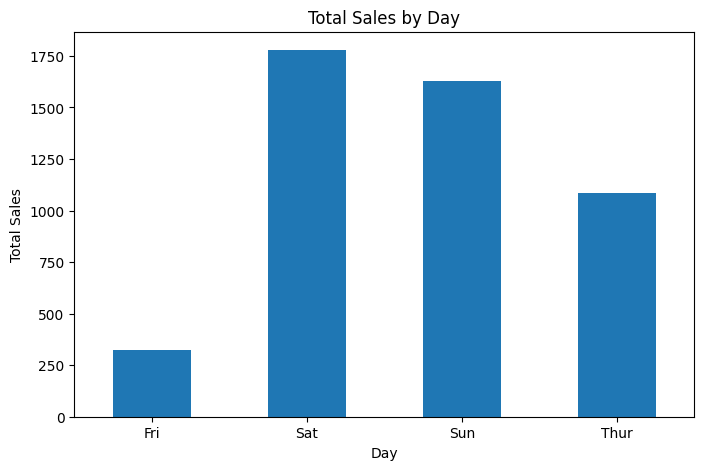

In [7]:
sales_by_day.plot(kind='bar', figsize=(8, 5))

plt.title('Total Sales by Day')
plt.xlabel('Day')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

In [8]:
daily_analysis = df.groupby('day').agg(
    total_sales=('total_bill', 'sum'),
    average_bill=('total_bill', 'mean'),
    number_of_transactions=('total_bill', 'count')
)

print(daily_analysis.round(2))

      total_sales  average_bill  number_of_transactions
day                                                    
Fri        325.88         17.15                      19
Sat       1778.40         20.44                      87
Sun       1627.16         21.41                      76
Thur      1083.33         17.76                      61


In [9]:
sales_by_time = df.groupby('time').agg(
    total_sales=('total_bill', 'sum'),
    average_bill=('total_bill', 'mean'),
    transactions=('total_bill', 'count')
)

print(sales_by_time.round(2))

        total_sales  average_bill  transactions
time                                           
Dinner      3660.30         20.80           176
Lunch       1154.47         17.23            67


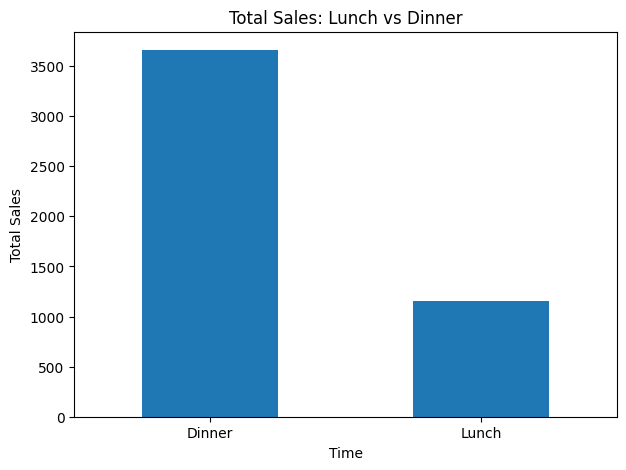

In [10]:
sales_by_time['total_sales'].plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Total Sales: Lunch vs Dinner')
plt.xlabel('Time')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

In [11]:
print("Correlation between total bill and tip:")
print(df['total_bill'].corr(df['tip']))

Correlation between total bill and tip:
0.6749978565456075


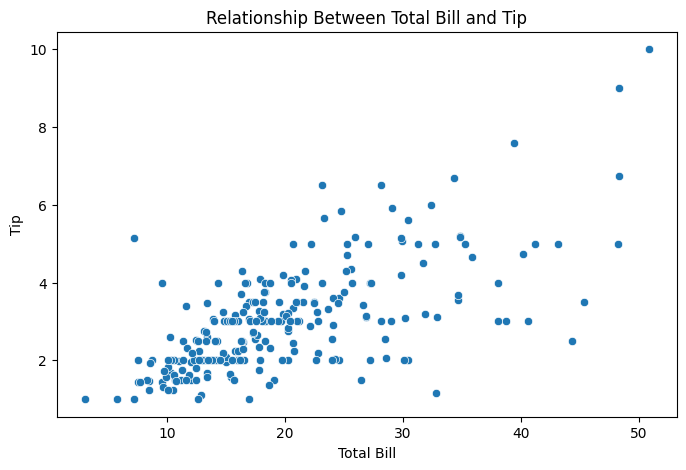

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='total_bill',
    y='tip'
)

plt.title('Relationship Between Total Bill and Tip')
plt.xlabel('Total Bill')
plt.ylabel('Tip')

plt.show()

In [14]:
tip_by_smoker = df.groupby('smoker').agg(
    average_tip=('tip', 'mean'),
    total_tip=('tip', 'sum'),
    transactions=('tip', 'count')
)

print(tip_by_smoker.round(2))

        average_tip  total_tip  transactions
smoker                                      
No             2.99     451.77           151
Yes            3.02     277.81            92


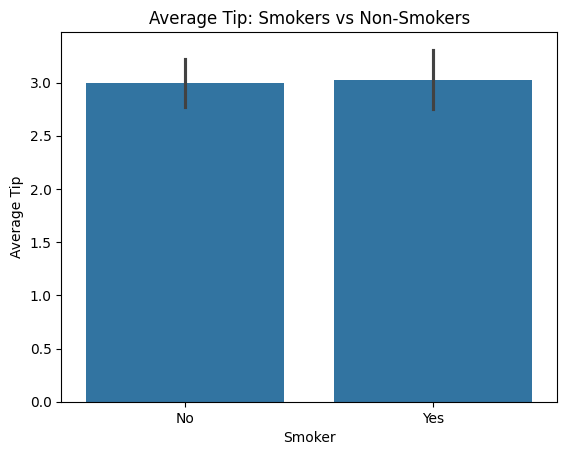

In [15]:
sns.barplot(
    data=df,
    x='smoker',
    y='tip'
)

plt.title('Average Tip: Smokers vs Non-Smokers')
plt.xlabel('Smoker')
plt.ylabel('Average Tip')
plt.show()

In [16]:
df['tip_percentage'] = (
    df['tip'] / df['total_bill']
) * 100

tip_percentage = df.groupby('smoker').agg(
    average_tip_percentage=('tip_percentage', 'mean')
)

print(tip_percentage.round(2))

        average_tip_percentage
smoker                        
No                       15.93
Yes                      16.33


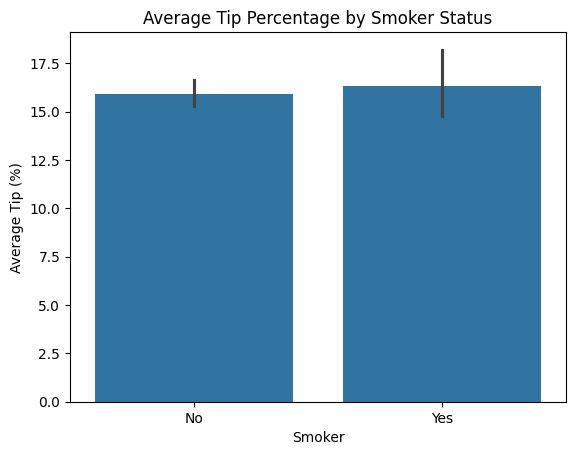

In [17]:
sns.barplot(
    data=df,
    x='smoker',
    y='tip_percentage'
)

plt.title('Average Tip Percentage by Smoker Status')
plt.xlabel('Smoker')
plt.ylabel('Average Tip (%)')
plt.show()

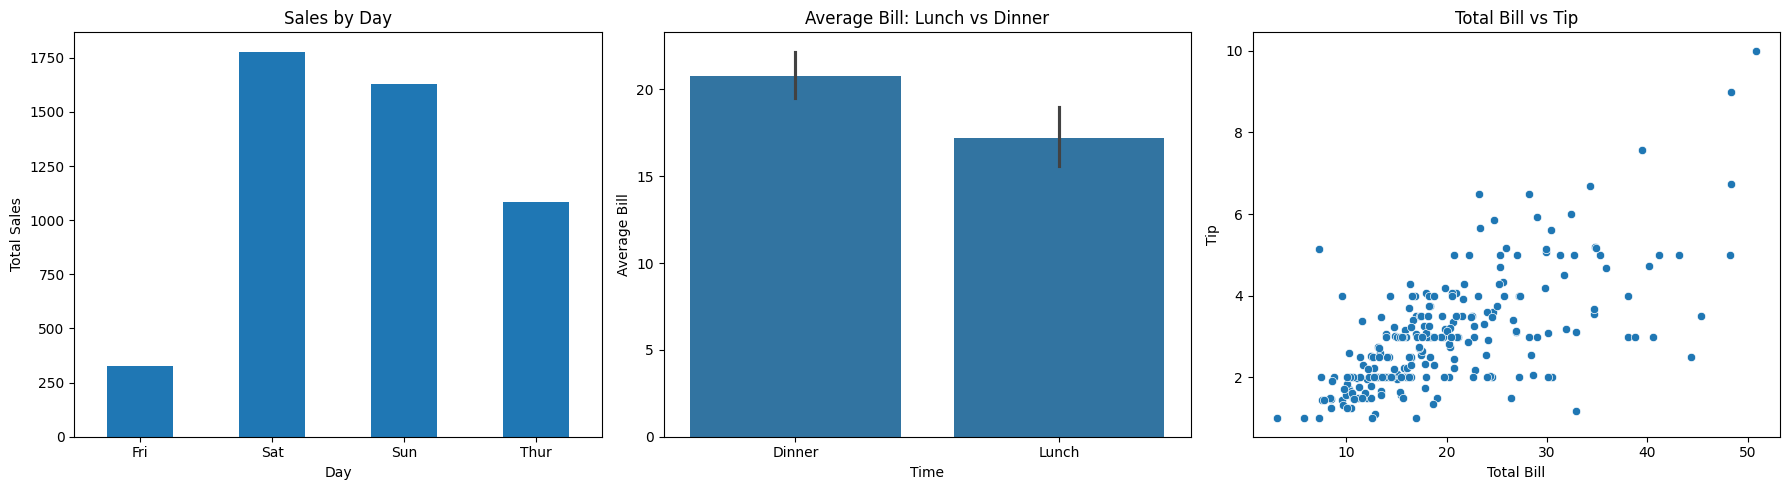

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Sales by Day
sales_by_day = df.groupby('day')['total_bill'].sum()

sales_by_day.plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Sales by Day')
axes[0].set_xlabel('Day')
axes[0].set_ylabel('Total Sales')
axes[0].tick_params(axis='x', rotation=0)


# Chart 2: Lunch vs Dinner
sns.barplot(
    data=df,
    x='time',
    y='total_bill',
    ax=axes[1]
)

axes[1].set_title('Average Bill: Lunch vs Dinner')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Average Bill')


# Chart 3: Bill vs Tip
sns.scatterplot(
    data=df,
    x='total_bill',
    y='tip',
    ax=axes[2]
)

axes[2].set_title('Total Bill vs Tip')
axes[2].set_xlabel('Total Bill')
axes[2].set_ylabel('Tip')

plt.tight_layout()
plt.show()